**DATA ANALYSIS PIPELINE**

This notebook runs on the combined PhilGEPS 1.5 + 2.0 dataset (`data/processed/philgeps_combined.parquet`), built from the raw files in `data/raw/` by `scripts/combine_raw.py`. Run `git lfs pull` and `python scripts/combine_raw.py` from the repository root first.

1. Reads the combined dataset and summarises the source files
2. Source summary (the raw files are already merged and harmonised by the script)
3. Calculates exact duplicate rows and drops them (we can decide what to do; dropping them here reduces size for analysis)
4. Missing values analysis
5. Visualisations of selected features
6. Data scoping analysis

**Why the combined file instead of reading `data/raw/*.csv` directly:** the raw files are not in one format, so a plain `pd.read_csv` loop fails on `1.5_2025_Q4.csv` (tab-delimited, Windows-1252) and silently skips it. The raw files also use three different column layouts, and the `2.0_2023`–`2.0_2025` files are byte-for-byte copies of the 1.5 files. Reading them all double-counts 2023–2025 and inflates the duplicate count. The script handles all of this once; see the README.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyarrow.parquet as pq
from pathlib import Path
import os
import warnings
warnings.filterwarnings('ignore')

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)

# Set paths relative to the repository, so the notebook runs on any machine.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").is_dir())
DATA_FILE = ROOT / "data" / "processed" / "philgeps_combined.parquet"
FIG_DIR = ROOT / "data" / "processed" / "figures"      # ignored by Git
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"Repository root: {ROOT}")
print(f"Combined dataset: {DATA_FILE} (exists: {DATA_FILE.exists()})")
if not DATA_FILE.exists():
    raise FileNotFoundError("Run `python scripts/combine_raw.py` from the repository root first.")

Repository root: c:\Users\Deborah Argayosa\Documents\GitHub\philgeps-ml-project
Combined dataset: c:\Users\Deborah Argayosa\Documents\GitHub\philgeps-ml-project\data\processed\philgeps_combined.parquet (exists: True)


## TASK 1: READ ALL DATA FILES

In [2]:
# The combined file holds every used raw file; Source File says where each row came from.
parquet_file = pq.ParquetFile(DATA_FILE)
all_columns = parquet_file.schema_arrow.names

# Long free-text columns are not needed for this analysis and would use several GB of memory.
FREE_TEXT = ["Notice Title", "Item Name", "Item Description", "Award Title", "UNSPSC Description",
             "Awardee Organization Name", "Awardee Joint Venture"]
load_columns = [c for c in all_columns if c not in FREE_TEXT]
string_columns = [c for c in load_columns
                  if str(parquet_file.schema_arrow.field(c).type) == "string" and c != "Bid Reference No."]

merged_df = pq.read_table(DATA_FILE, columns=load_columns).to_pandas(categories=string_columns)

file_info = (merged_df.groupby(["Source System", "Source File"], observed=True).size()
             .rename("Rows").reset_index().rename(columns={"Source File": "File"}))
raw_dir = ROOT / "data" / "raw"
file_info["Size (MB)"] = [round(os.path.getsize(raw_dir / f) / (1024 * 1024), 2) for f in file_info["File"]]

print(f"Found {len(file_info)} source files in the combined dataset:\n")
for i, f in enumerate(file_info["File"], 1):
    print(f"{i}. {f}")
skipped = sorted(set(os.listdir(raw_dir)) - set(file_info["File"]))
print(f"\nRaw files not used ({len(skipped)}; byte-for-byte copies of the 1.5 files): {', '.join(skipped)}")

Found 18 source files in the combined dataset:

1. 1.5_2023_Q1.csv
2. 1.5_2023_Q2.csv
3. 1.5_2023_Q3.csv
4. 1.5_2023_Q4.csv
5. 1.5_2024_Q1.csv
6. 1.5_2024_Q2.csv
7. 1.5_2024_Q3.csv
8. 1.5_2024_Q4.csv
9. 1.5_2025_Q1.csv
10. 1.5_2025_Q2.csv
11. 1.5_2025_Q3.csv
12. 1.5_2025_Q4.csv
13. 1.5_2026_Q1.csv
14. 1.5_2026_Q2.csv
15. 1.5_2026_Q3.csv
16. 2.0_2026_Q1.csv
17. 2.0_2026_Q2.csv
18. 2.0_2026_Q3.csv

Raw files not used (12; byte-for-byte copies of the 1.5 files): 2.0_2023_Q1.csv, 2.0_2023_Q2.csv, 2.0_2023_Q3.csv, 2.0_2023_Q4.csv, 2.0_2024_Q1.csv, 2.0_2024_Q2.csv, 2.0_2024_Q3.csv, 2.0_2024_Q4.csv, 2.0_2025_Q1.csv, 2.0_2025_Q2.csv, 2.0_2025_Q3.csv, 2.0_2025_Q4.csv


## TASK 2 & 3: MERGE DATA AND SOURCE SUMMARY

In [3]:
print(f"Merged DataFrame: {merged_df.shape[0]:,} rows × {merged_df.shape[1]} columns "
      f"({len(FREE_TEXT)} free-text columns not loaded)")
print(f"\nColumn Names:")
print(merged_df.columns.tolist())

# Summary of source files
summary_df = file_info
print("\n" + "="*80)
print("SOURCE FILES SUMMARY")
print("="*80)
print(summary_df.to_string(index=False))
print(f"\nTotal Size: {summary_df['Size (MB)'].sum():.2f} MB")
print(f"Total Rows: {summary_df['Rows'].sum():,}")
print(f"Columns in the combined dataset: {len(all_columns)}")

Merged DataFrame: 6,059,201 rows × 47 columns (7 free-text columns not loaded)

Column Names:
['Source System', 'Source File', 'Source Quarter', 'Procuring Entity (PE)', 'Region', 'Province', 'City/Municipality', 'Government Branch', 'PE Organization Type', 'PE Organization Type (Grouped)', 'Bid Reference No.', 'Solicitation No.', 'Classification', 'Procurement Mode', 'Procurement Mode (Grouped)', 'Business Category', 'Funding Source', 'Funding Instrument', 'Trade Agreement', 'Approved Budget of the Contract', 'Published Date', 'Closing Date', 'Area of Delivery', 'Contract Duration', 'Calendar Type', 'Lot Type', 'Line Item No', 'Item Code', 'Quantity', 'UOM', 'Item Budget', 'Bid Notice Status', 'Award Reference No.', 'UNSPSC Code', 'Published Date(Award)', 'Award Date', 'Contract Amount', 'Award Notice Status', 'Notice to Proceed Date', 'Contract Effectivity Date', 'Contract End Date', 'Awardee OrgID', 'Country of Awardee', 'Region of Awardee', 'Province of Awardee', 'City/Municipality

## TASK 4.1: DUPLICATE ANALYSIS

In [4]:
print("="*80)
print("DUPLICATE ANALYSIS")
print("="*80)

before_drop = len(merged_df)
print(f"\nRows before removing duplicates: {before_drop:,}")

# Exact duplicates across all PhilGEPS columns (free text included), computed by hashing each row
# while streaming the file. The lineage columns Source File / Source Quarter are left out so that
# the same record exported in two files also counts as a duplicate.
hashes = []
for batch in parquet_file.iter_batches(batch_size=200_000):
    frame = batch.to_pandas().drop(columns=["Source File", "Source Quarter"])
    hashes.append(pd.util.hash_pandas_object(frame, index=False).to_numpy())
duplicate_mask = pd.Series(np.concatenate(hashes)).duplicated().to_numpy()
del hashes

duplicates = int(duplicate_mask.sum())
print(f"Duplicate rows found: {duplicates:,}")

merged_df_clean = merged_df.loc[~duplicate_mask].reset_index(drop=True)
del merged_df
after_drop = len(merged_df_clean)
duplicate_pct = (before_drop - after_drop) / before_drop * 100
print(f"Rows after removing duplicates: {after_drop:,}")
print(f"Rows removed: {before_drop - after_drop:,} ({duplicate_pct:.2f}%)")

print(f"\n✓ Cleaned dataset: {merged_df_clean.shape[0]:,} rows × {merged_df_clean.shape[1]} columns")

DUPLICATE ANALYSIS

Rows before removing duplicates: 6,059,201


Duplicate rows found: 673,921


Rows after removing duplicates: 5,385,280
Rows removed: 673,921 (11.12%)

✓ Cleaned dataset: 5,385,280 rows × 47 columns


## TASK 4.2: MISSING VALUES AND DATA TYPES

In [5]:
print("="*80)
print("MISSING VALUES SUMMARY")
print("="*80)

missing = pd.DataFrame({
    'Column': merged_df_clean.columns,
    'Missing Count': merged_df_clean.isnull().sum().values,
    'Missing %': (merged_df_clean.isnull().sum().values / len(merged_df_clean) * 100).round(2)
})
missing_sorted = missing[missing['Missing Count'] > 0].sort_values('Missing %', ascending=False)

if len(missing_sorted) > 0:
    print("\nColumns with missing values:")
    print(missing_sorted.to_string(index=False))
else:
    print("\n✓ No missing values found!")

print("\n" + "="*80)
print("DATA TYPES SUMMARY")
print("="*80)

dtype_summary = pd.DataFrame({
    'Column': merged_df_clean.columns,
    'Data Type': merged_df_clean.dtypes.values
})
print("\n" + dtype_summary.to_string(index=False))

MISSING VALUES SUMMARY



Columns with missing values:
                         Column  Missing Count  Missing %
                  Awardee OrgID        5382769      99.95
                      Item Code        5240389      97.31
                       Lot Type        5240351      97.31
               Solicitation No.        4671699      86.75
         Notice to Proceed Date        4119261      76.49
              Contract End Date        4119261      76.49
      Contract Effectivity Date        4119261      76.49
                   Awardee Size        3793569      70.44
                    UNSPSC Code        3733272      69.32
              Region of Awardee        3733253      69.32
            Province of Awardee        3732383      69.31
   City/Municipality of Awardee        3731365      69.29
             Country of Awardee        3730097      69.26
          Published Date(Award)        3729401      69.25
            Award Notice Status        3729401      69.25
            Award Reference No.        372

## TASK 4.3: COUNT PLOTS WITH PERCENTAGES

In [6]:
print("="*80)
print("COLUMN AVAILABILITY CHECK")
print("="*80)

cols_to_explore = [
    "Procuring Entity (PE)", "Region", "Province", "City/Municipality",
    "Government Branch", "PE Organization Type",
    "PE Organization Type (Grouped)", "Classification",
    "Procurement Mode", "Business Category", "Funding Source"
]

available_cols = [col for col in cols_to_explore if col in merged_df_clean.columns]
missing_cols = [col for col in cols_to_explore if col not in merged_df_clean.columns]

print(f"\nColumns requested: {len(cols_to_explore)}")
print(f"Columns available: {len(available_cols)}")
print(f"Columns missing: {len(missing_cols)}")

print(f"\nAvailable columns:")
for col in available_cols:
    print(f"  ✓ {col}")

if missing_cols:
    print(f"\nMissing columns:")
    for col in missing_cols:
        print(f"  ✗ {col}")

COLUMN AVAILABILITY CHECK

Columns requested: 11
Columns available: 11
Columns missing: 0

Available columns:
  ✓ Procuring Entity (PE)
  ✓ Region
  ✓ Province
  ✓ City/Municipality
  ✓ Government Branch
  ✓ PE Organization Type
  ✓ PE Organization Type (Grouped)
  ✓ Classification
  ✓ Procurement Mode
  ✓ Business Category
  ✓ Funding Source



COUNT ANALYSIS FOR EACH COLUMN

1. Procuring Entity (PE)
--------------------------------------------------------------------------------
Unique values: 44642
                                                       Value  Count  Percentage
                  BATAAN GENERAL HOSPITAL AND MEDICAL CENTER  33967        0.63
                  BICOL REGIONAL HOSPITAL AND MEDICAL CENTER  28996        0.54
               RESEARCH INSTITUTE FOR TROPICAL MEDICINE, DOH  26603        0.49
                       VETERANS MEMORIAL MEDICAL CENTER, DND  26131        0.49
DEPARTMENT OF HEALTH - TREATMENT AND REHABILITATION CENTER -  24022        0.45
                                          PROVINCE OF BATAAN  23827        0.44
                                        BICOL MEDICAL CENTER  20175        0.37
                          CITY OF DUMAGUETE, NEGROS ORIENTAL  16153        0.30
BICOL REGION GENERAL HOSPITAL AND GERIATRIC MEDICAL CENTER(F  15431        0.29
                         REGION II TRAUM

   ✓ Graph saved: plot_01_Procuring_Entity_PE.png


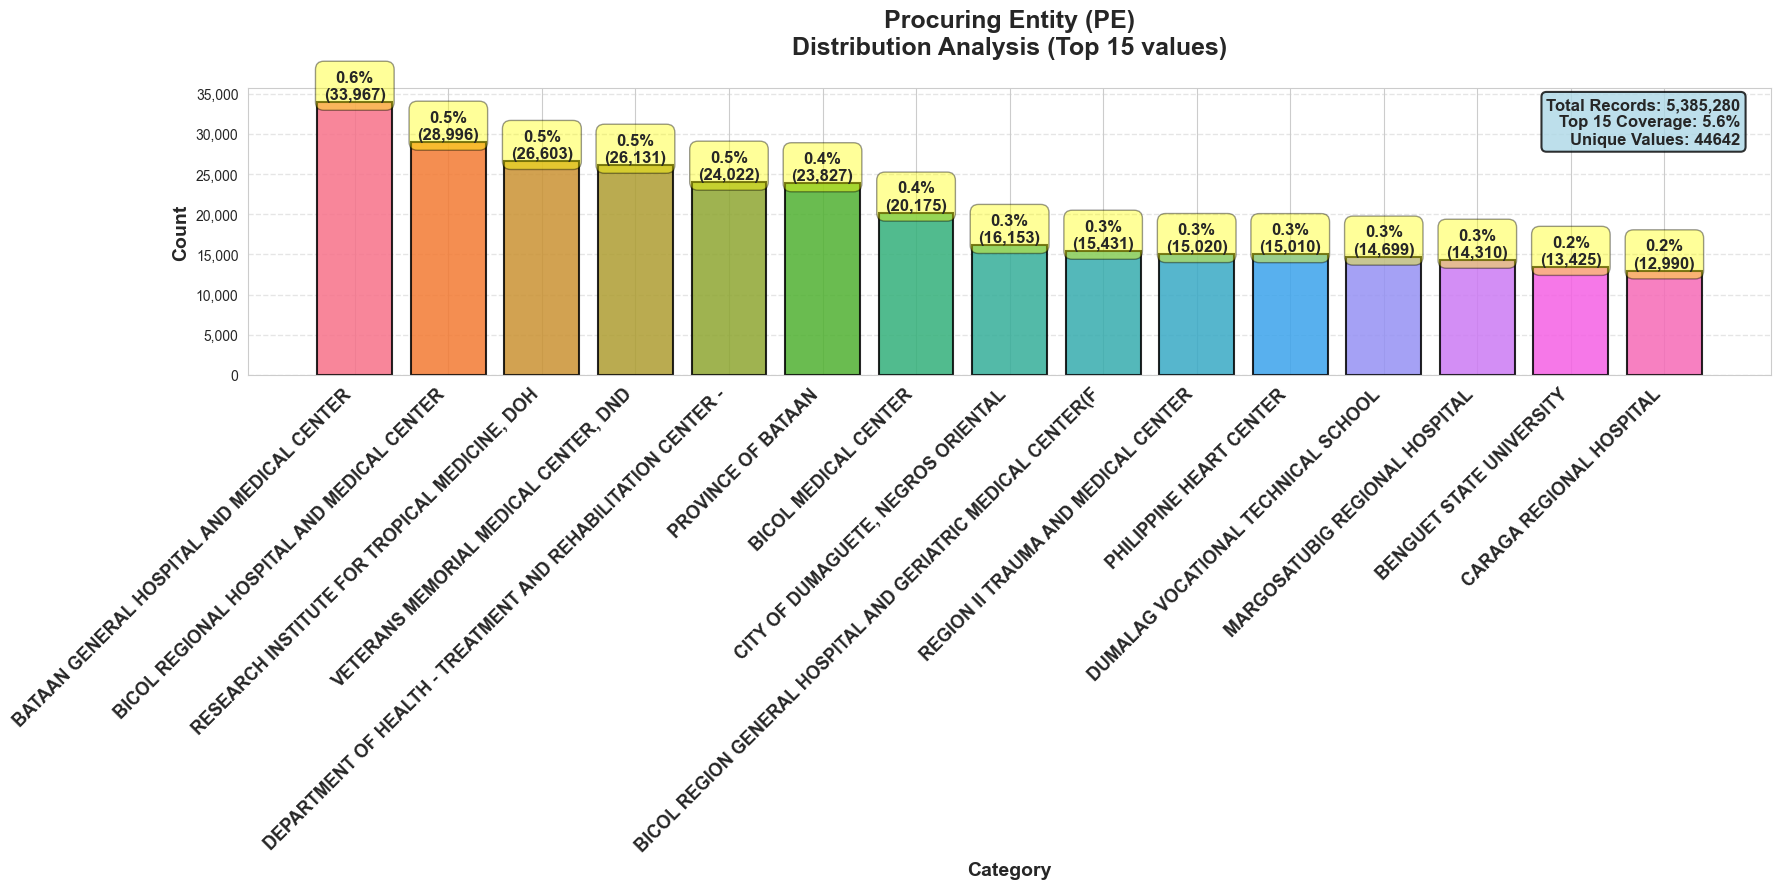


2. Region
--------------------------------------------------------------------------------
Unique values: 19
      Value  Count  Percentage
        NCR 746697       13.87
   Region X 484645        9.00
Region IV-A 445862        8.28
 Region III 391307        7.27
 Region VII 379342        7.04
  Region VI 348172        6.47
   Region V 342473        6.36
Region VIII 302659        5.62
  Region IX 261532        4.86
  Region XI 256969        4.77


   ✓ Graph saved: plot_02_Region.png


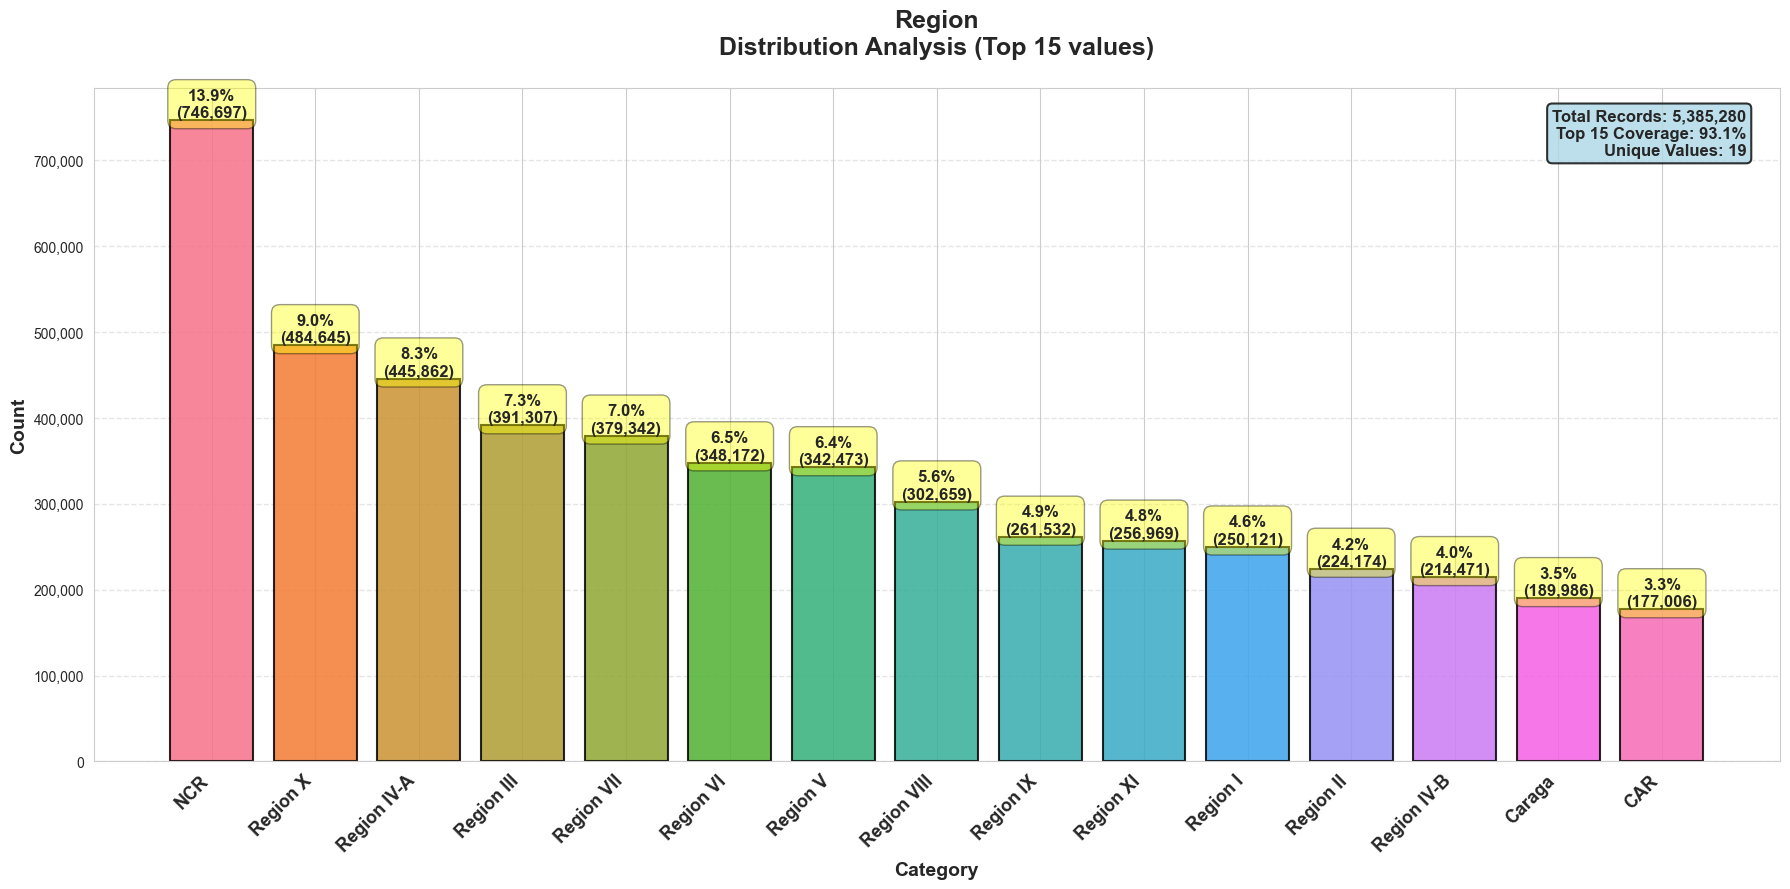


3. Province
--------------------------------------------------------------------------------
Unique values: 130
            Value  Count  Percentage
     Metro Manila 746565       13.86
         Bukidnon 234325        4.35
             Cebu 216130        4.01
 Misamis Oriental 165300        3.07
           Iloilo 162734        3.02
Zamboanga Del Sur 161550        3.00
Negros Occidental 142681        2.65
            Leyte 141912        2.64
    Camarines Sur 139933        2.60
    Davao Del Sur 132294        2.46


   ✓ Graph saved: plot_03_Province.png


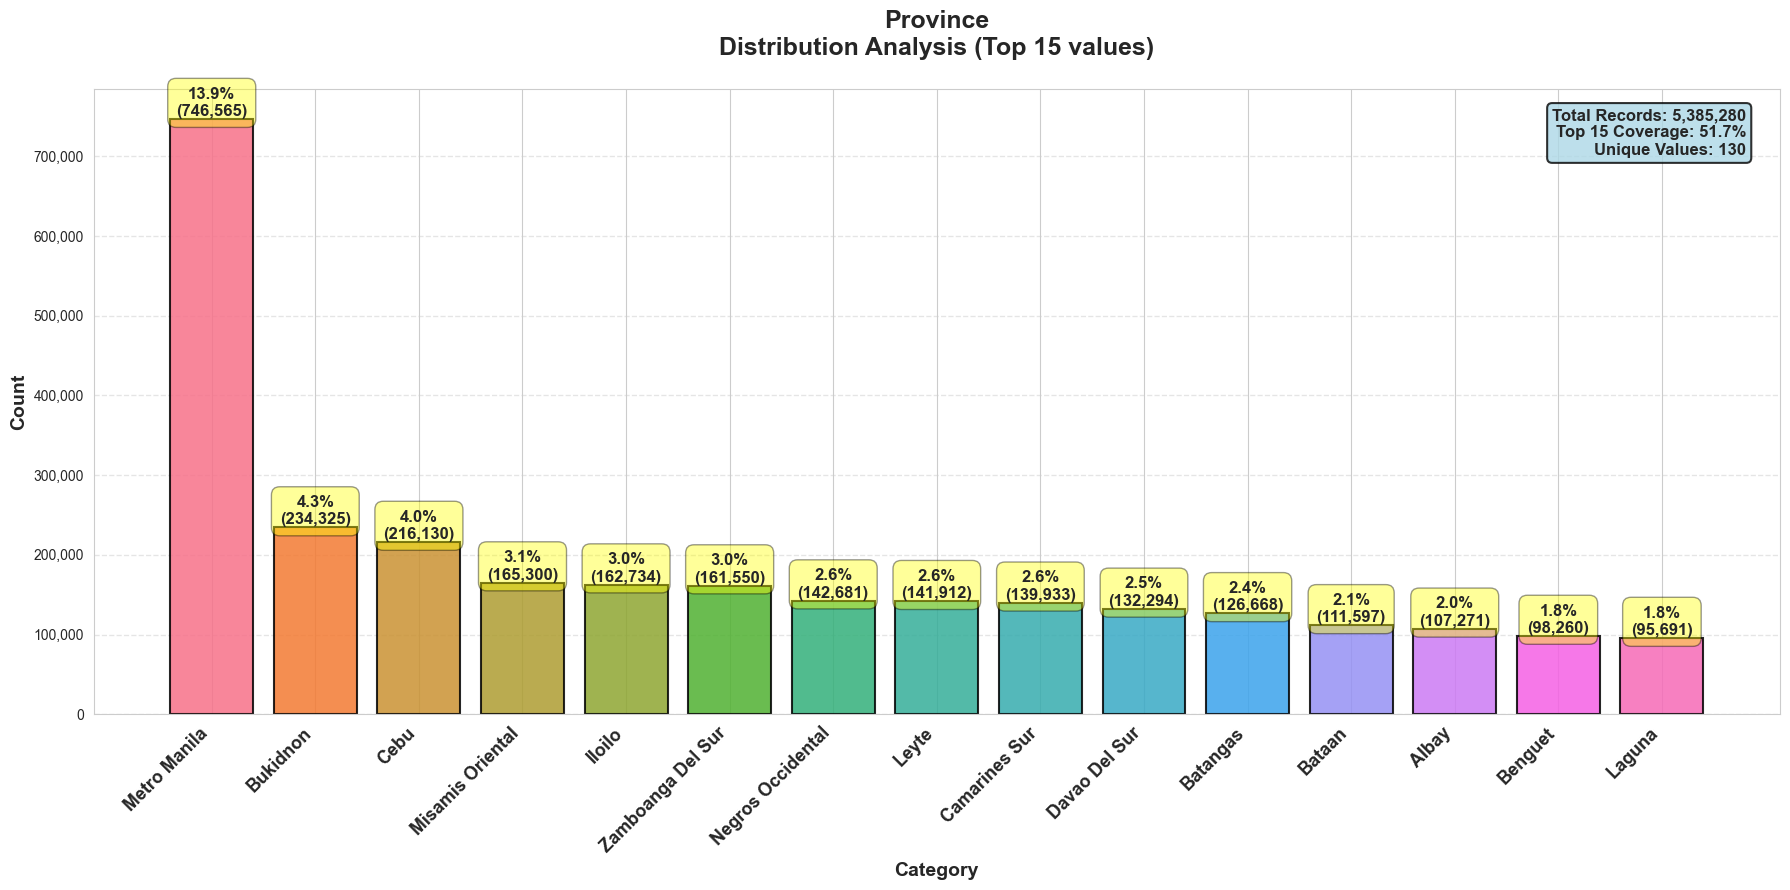


4. City/Municipality
--------------------------------------------------------------------------------
Unique values: 1462
              Value  Count  Percentage
        Quezon City 294737        5.47
             Manila 140871        2.62
  San Fernando City  90195        1.67
         Davao City  88230        1.64
          Cebu City  86650        1.61
        Iloilo City  75203        1.40
     Zamboanga City  74917        1.39
       Balanga City  70738        1.31
       Legazpi City  69833        1.30
Cagayan De Oro City  66202        1.23


   ✓ Graph saved: plot_04_City_Municipality.png


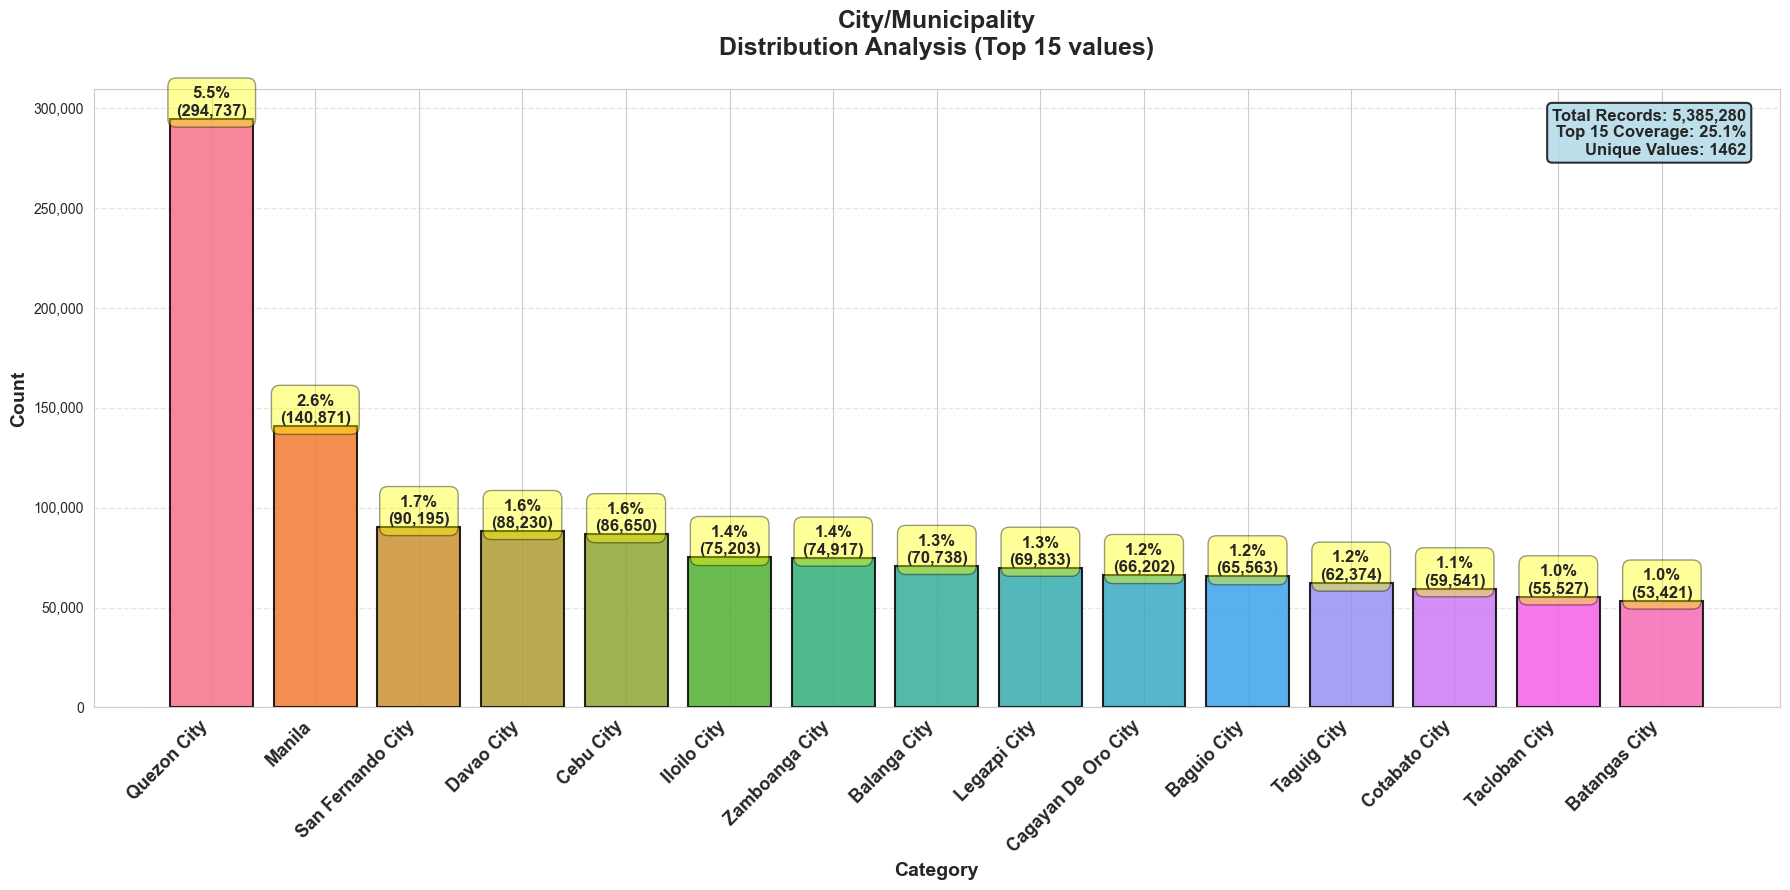


5. Government Branch
--------------------------------------------------------------------------------
Unique values: 7
                      Value   Count  Percentage
                  Executive 5349137       99.33
                Legislative   21853        0.41
                  Judiciary   10713        0.20
      Constitutional Office    2638        0.05
Local Government Unit (LGU)     791        0.01
   Non-benefit Organization      82        0.00
Non-Government Organization      64        0.00


   ✓ Graph saved: plot_05_Government_Branch.png


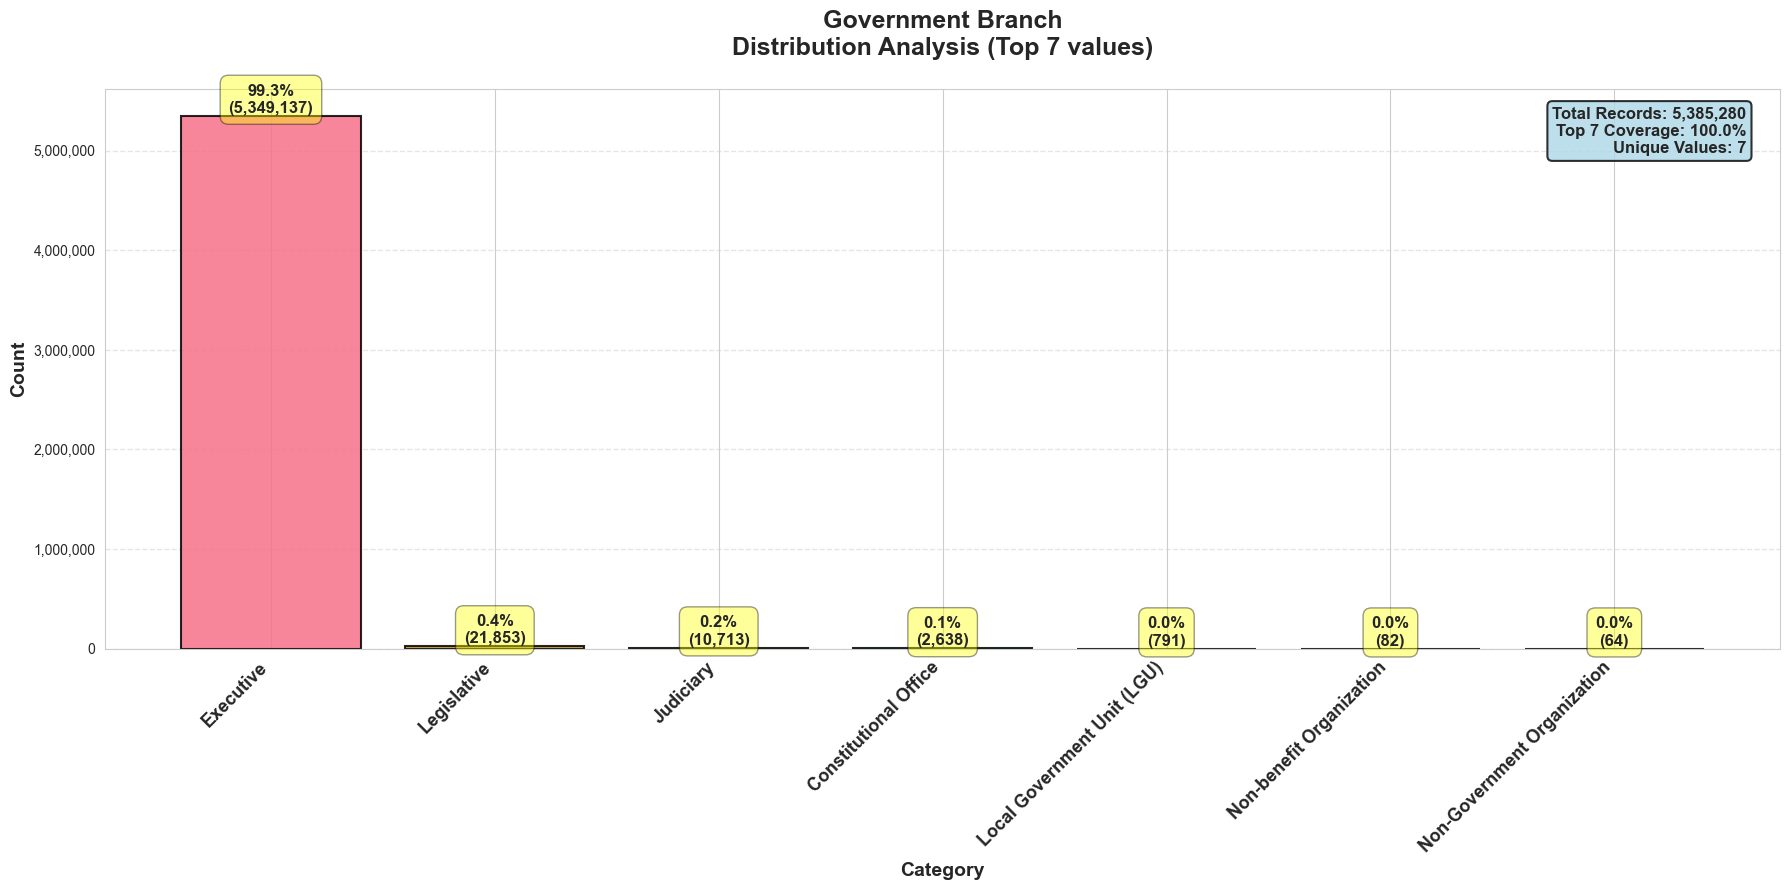


6. PE Organization Type
--------------------------------------------------------------------------------
Unique values: 16
                                         Value   Count  Percentage
                          Municipal Government 1116101       20.73
                                    Department  917808       17.04
                                      Barangay  484609        9.00
                               City Government  450850        8.37
                                      Hospital  443111        8.23
Government Owned and/or Controlled Corp.(GOCC)  350272        6.50
                         Provincial Government  346831        6.44
                                    Elementary  296386        5.50
                               Attached Agency  286217        5.31
          State Universities or Colleges (SUC)  273418        5.08


   ✓ Graph saved: plot_06_PE_Organization_Type.png


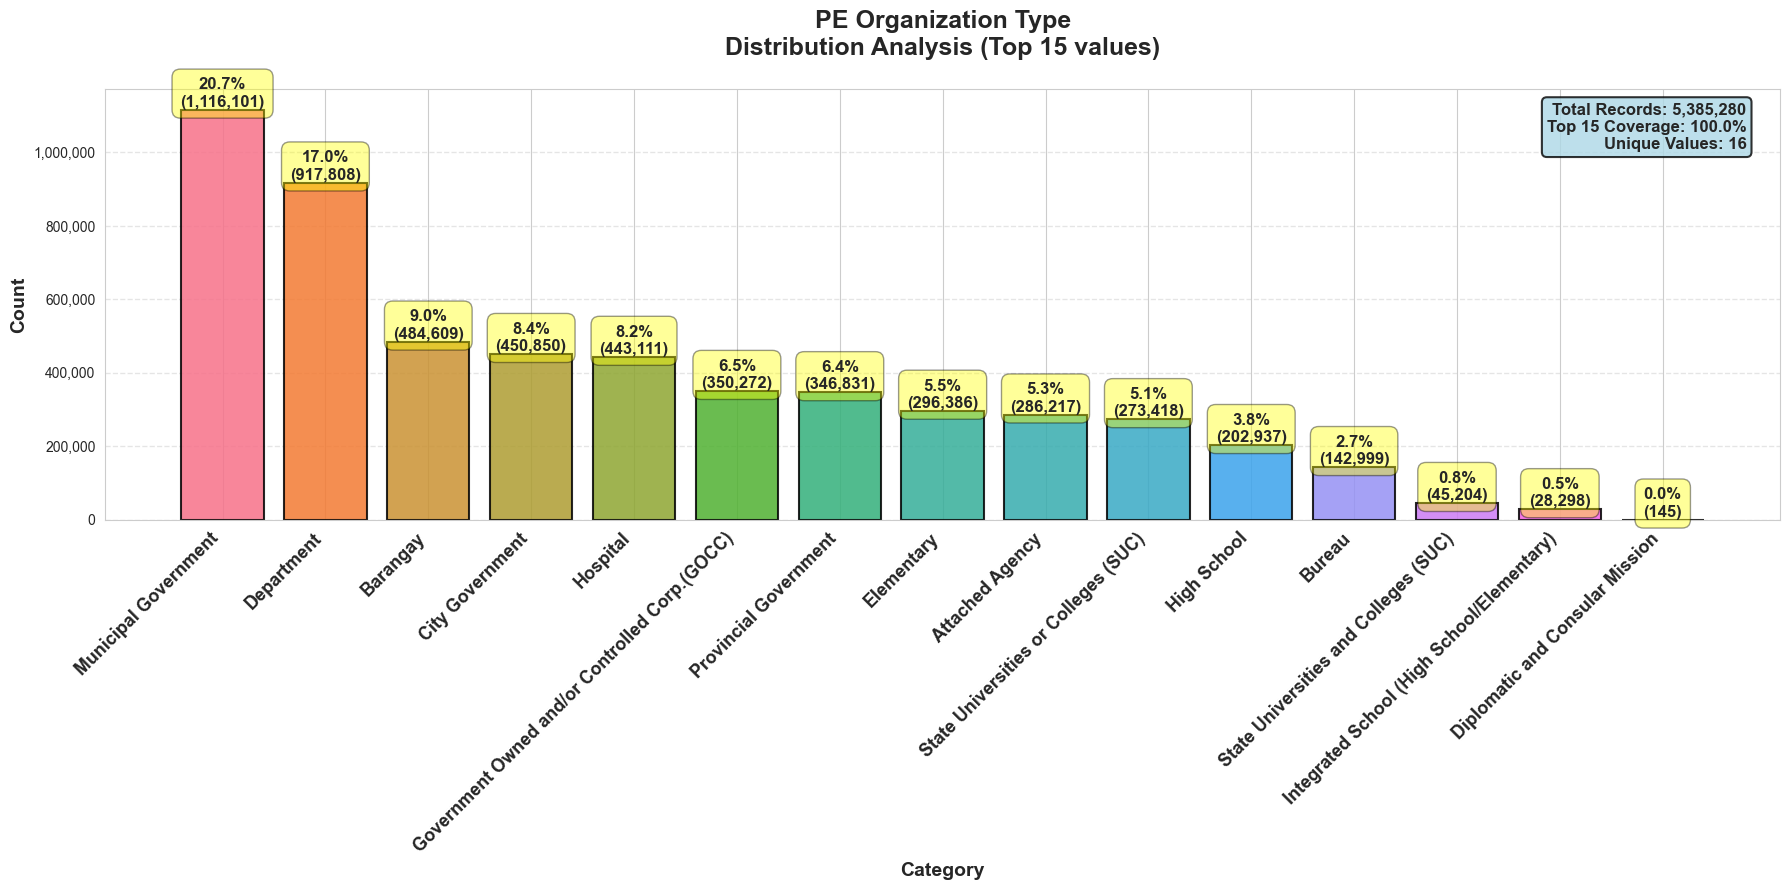


7. PE Organization Type (Grouped)
--------------------------------------------------------------------------------
Unique values: 5
                                              Value   Count  Percentage
                       Local Government Units (LGU) 2398391       44.54
                 National Government Agencies (NGA) 2317901       43.04
Government Owned and Controlled Corporations (GOCC)  350272        6.50
              State Universities and Colleges (SUC)  318622        5.92
                                             Others       8        0.00


   ✓ Graph saved: plot_07_PE_Organization_Type_Grouped.png


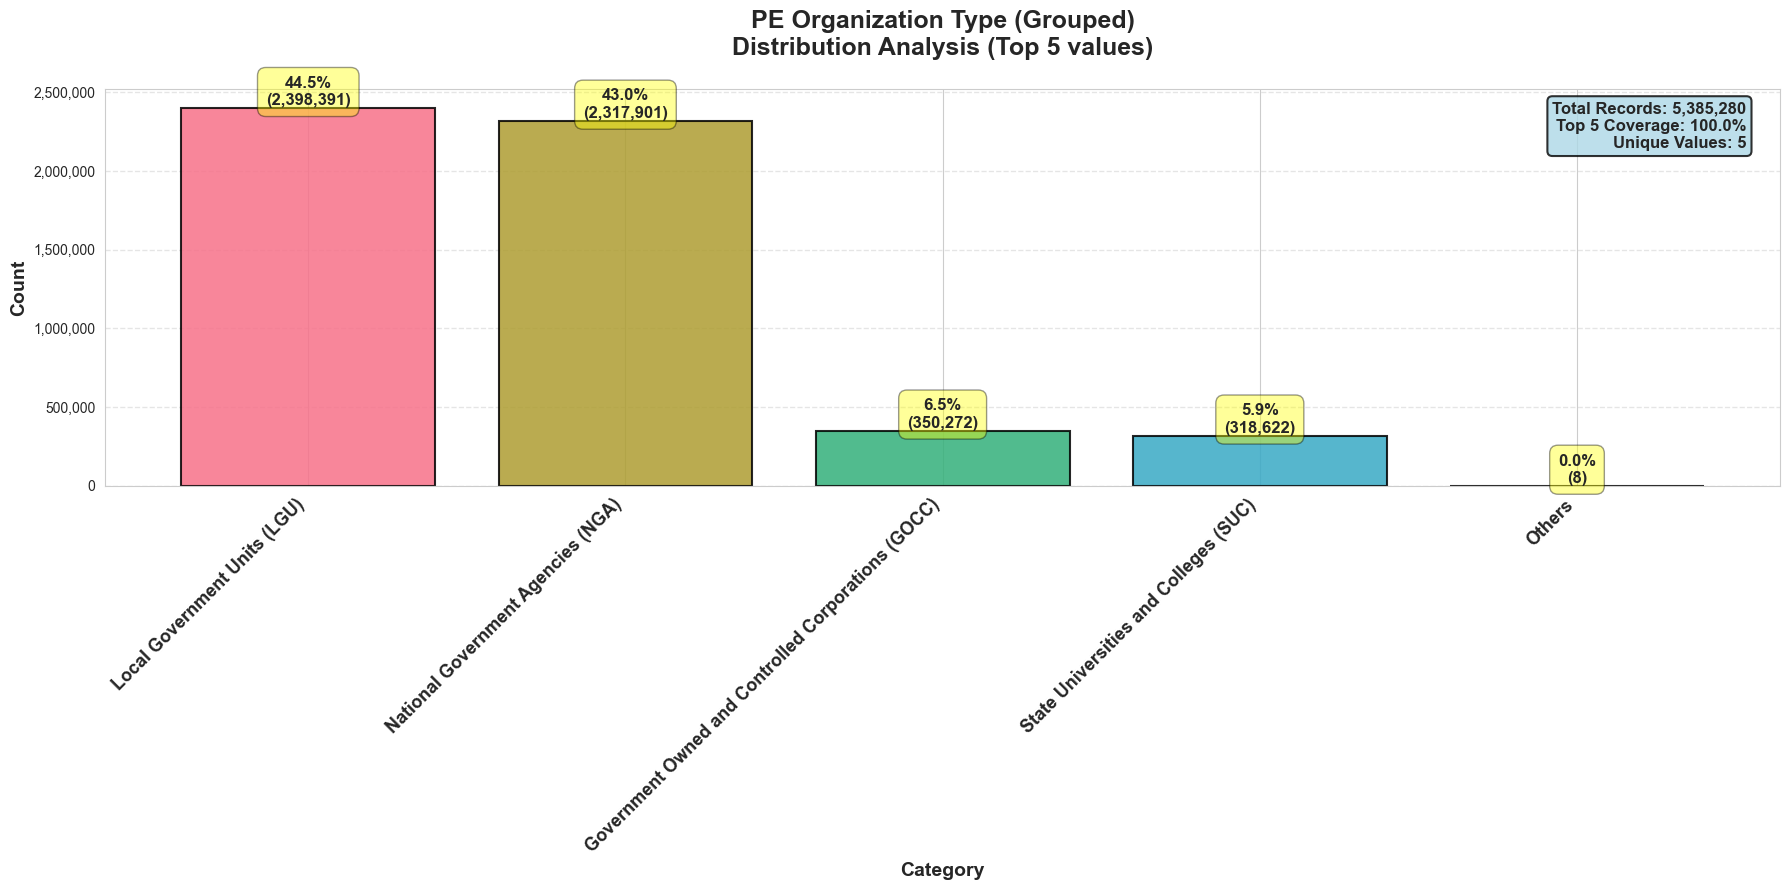


8. Classification
--------------------------------------------------------------------------------
Unique values: 4
                           Value   Count  Percentage
                           Goods 4602694       85.47
                     Civil Works  580598       10.78
Goods - General Support Services  179106        3.33
             Consulting Services   22879        0.42


   ✓ Graph saved: plot_08_Classification.png


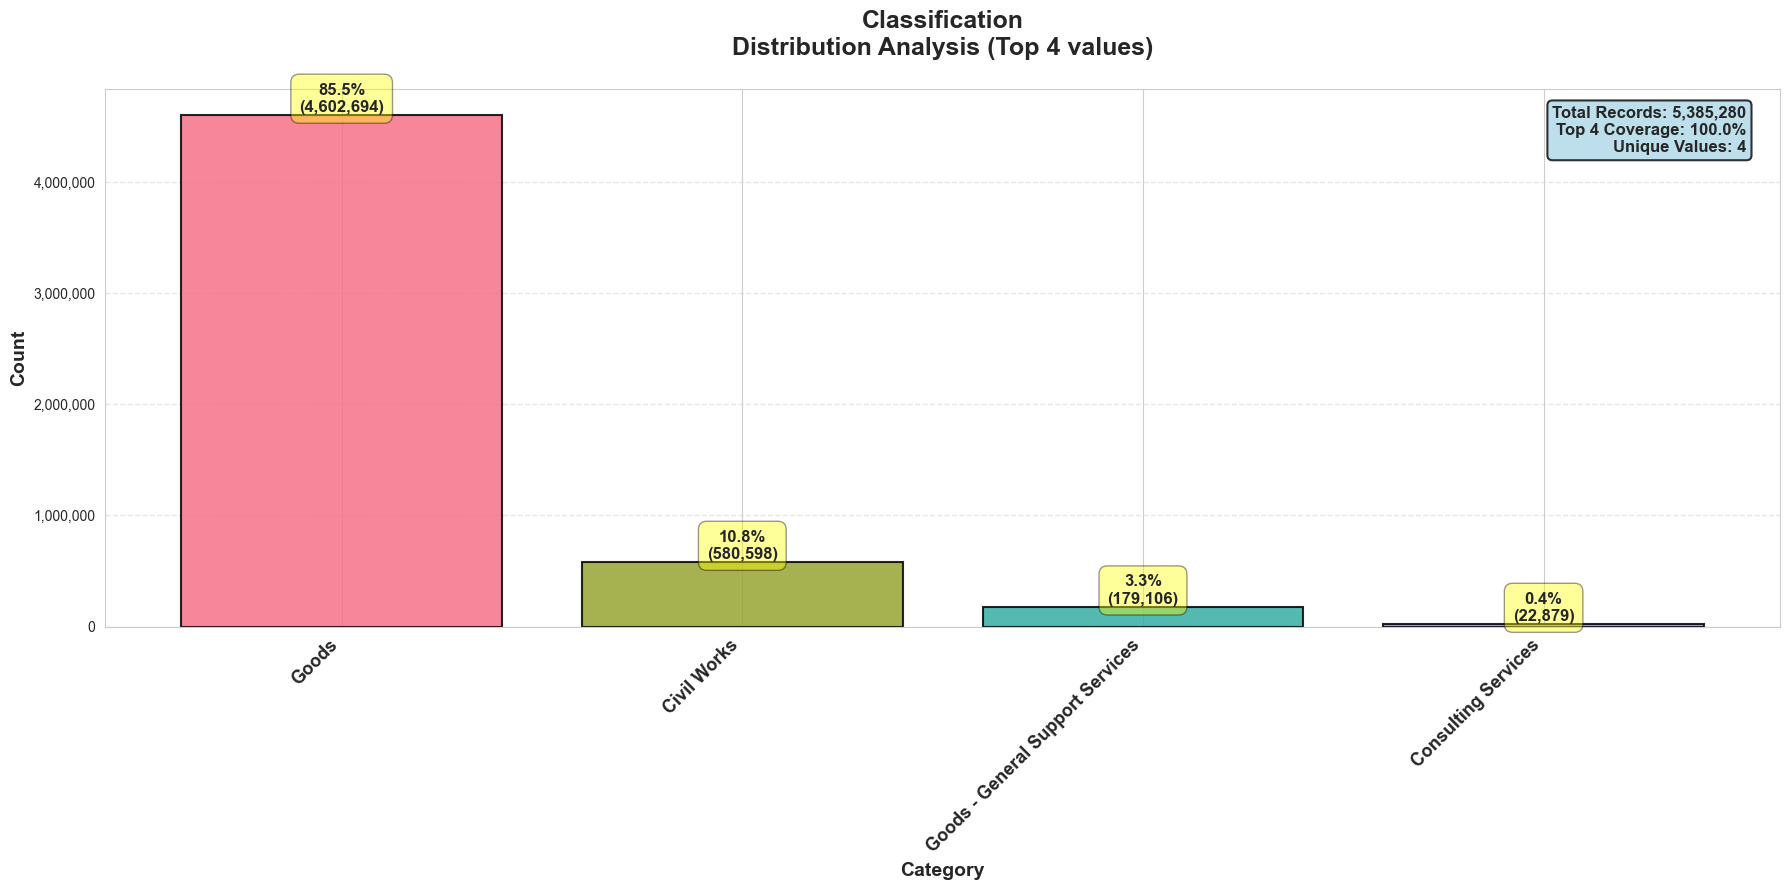


9. Procurement Mode
--------------------------------------------------------------------------------
Unique values: 40
                                                                Value   Count  Percentage
         Negotiated Procurement - Small Value Procurement (Sec. 53.9) 2148019       39.89
                                                       Public Bidding 1783947       33.13
Shopping - Ordinary/Regular Office Supplies & Equipment (Sec. 52.1.b)  738520       13.71
           Negotiated Procurement - Small Value Procurement (Sec. 34)  343038        6.37
                                              Small Value Procurement   86835        1.61
             Negotiated Procurement - Two Failed Biddings (Sec. 53.1)   84672        1.57
                                 Competitive Bidding (Public Bidding)   54828        1.02
         Negotiated Procurement - Lease of Real Property (Sec. 53.10)   41453        0.77
                                         Direct Contracting (Sec. 50) 

   ✓ Graph saved: plot_09_Procurement_Mode.png


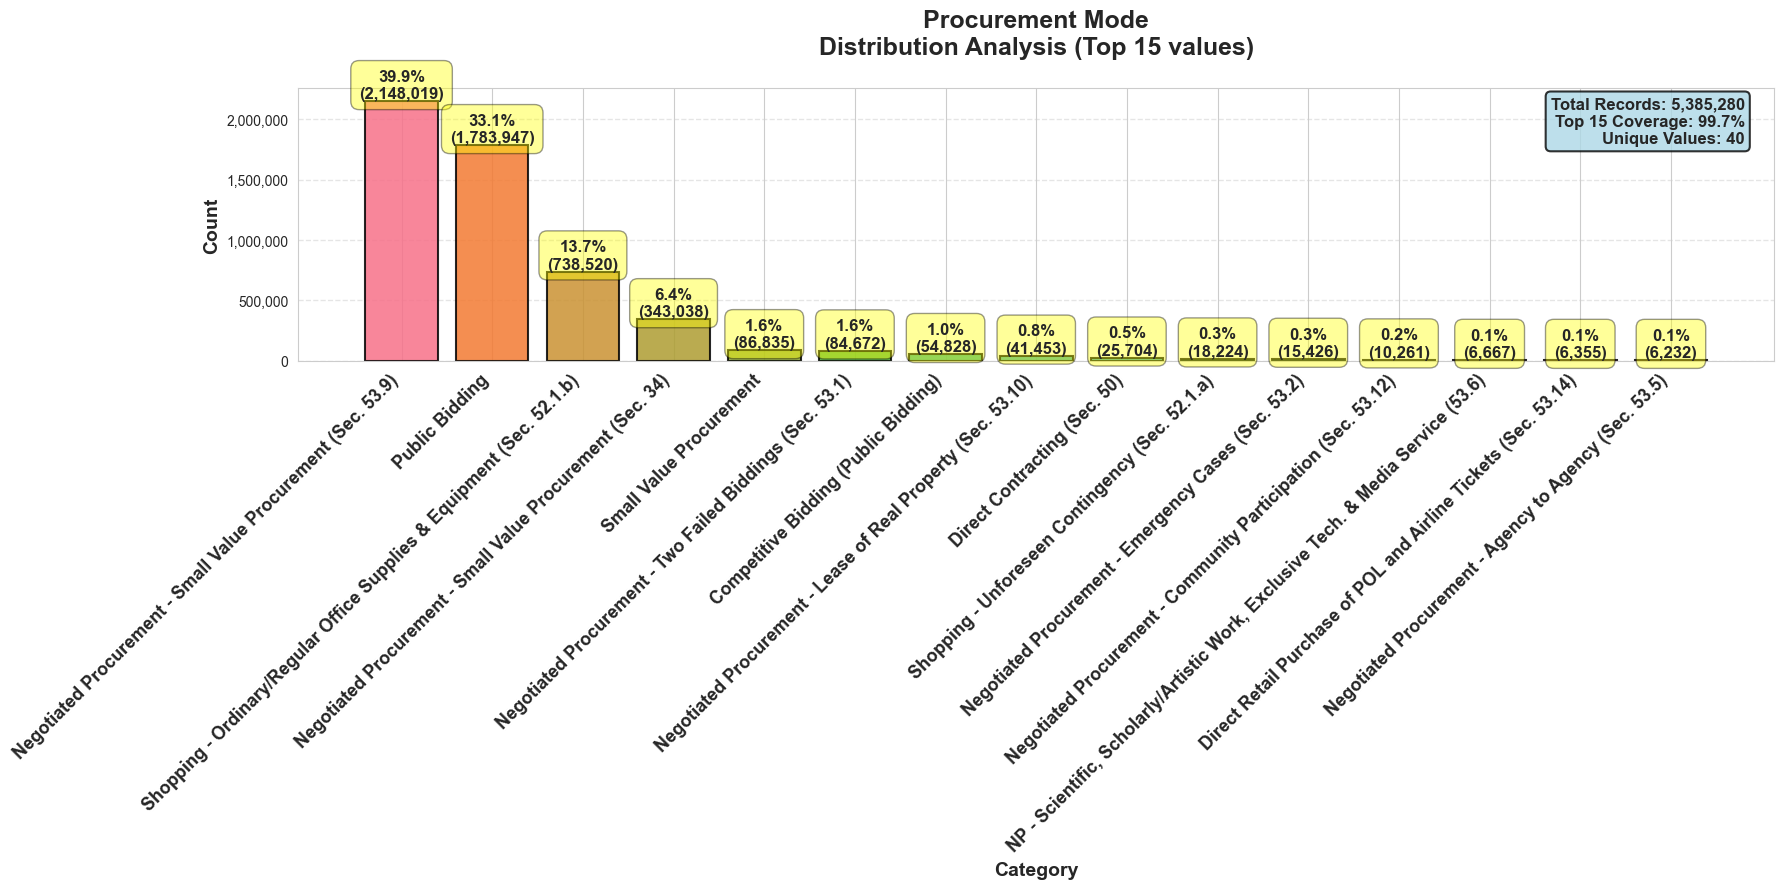


10. Business Category
--------------------------------------------------------------------------------
Unique values: 554
                                     Value  Count  Percentage
                     Construction Projects 539182       10.01
       Construction Materials and Supplies 436716        8.11
               Office Supplies and Devices 327213        6.08
                         Catering Services 303620        5.64
                       General Merchandise 302444        5.62
 Office Equipment Supplies and Consumables 293875        5.46
Medical Supplies and Laboratory Instrument 245424        4.56
                       Drugs and Medicines 194058        3.60
                                Food Stuff 174071        3.23
                          Office Equipment 131117        2.43


   ✓ Graph saved: plot_10_Business_Category.png


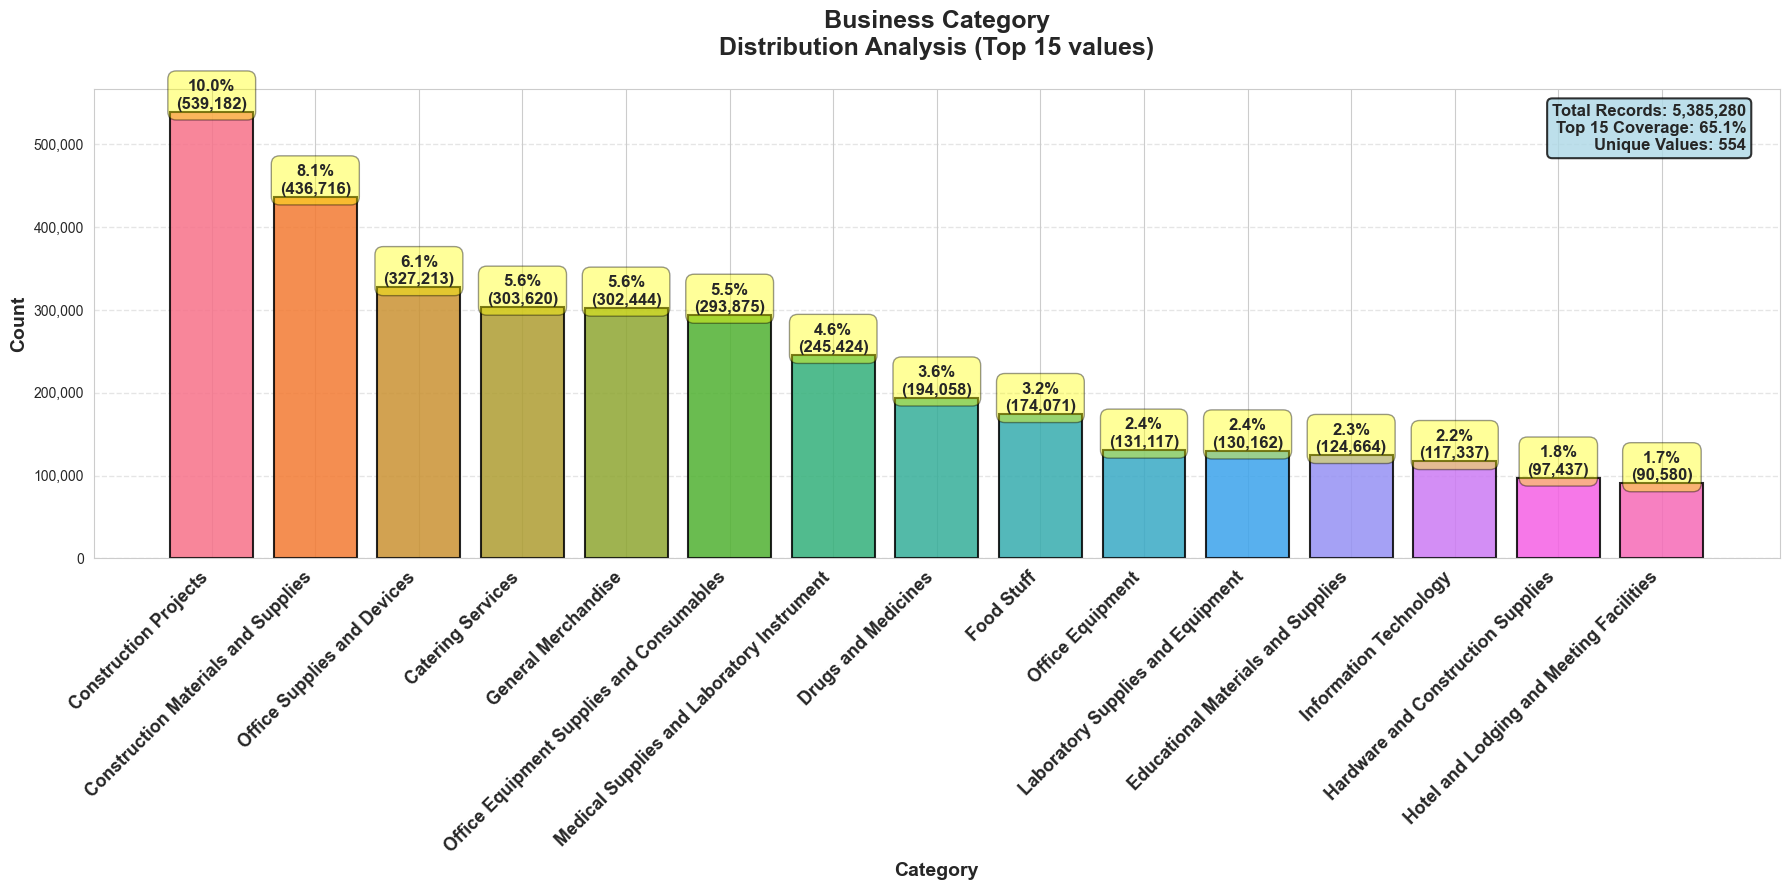


11. Funding Source
--------------------------------------------------------------------------------
Unique values: 14
                                                           Value   Count  Percentage
                             Government of the Philippines (GOP) 5082308       94.37
                                                          Others  127482        2.37
                                  Regular Agency Fund (01000000)  116858        2.17
                                                 World Bank (WB)   19597        0.36
                           Internally Generated Funds (05000000)   17735        0.33
                                    Asian Development Bank (ADB)    9942        0.18
                                       Trust Receipts (07000000)    3740        0.07
Special Account - Locally Funded/Domestic Grants Fund (03000000)    2632        0.05
                               Business Related Funds (06000000)    1743        0.03
                       Foreign 

   ✓ Graph saved: plot_11_Funding_Source.png


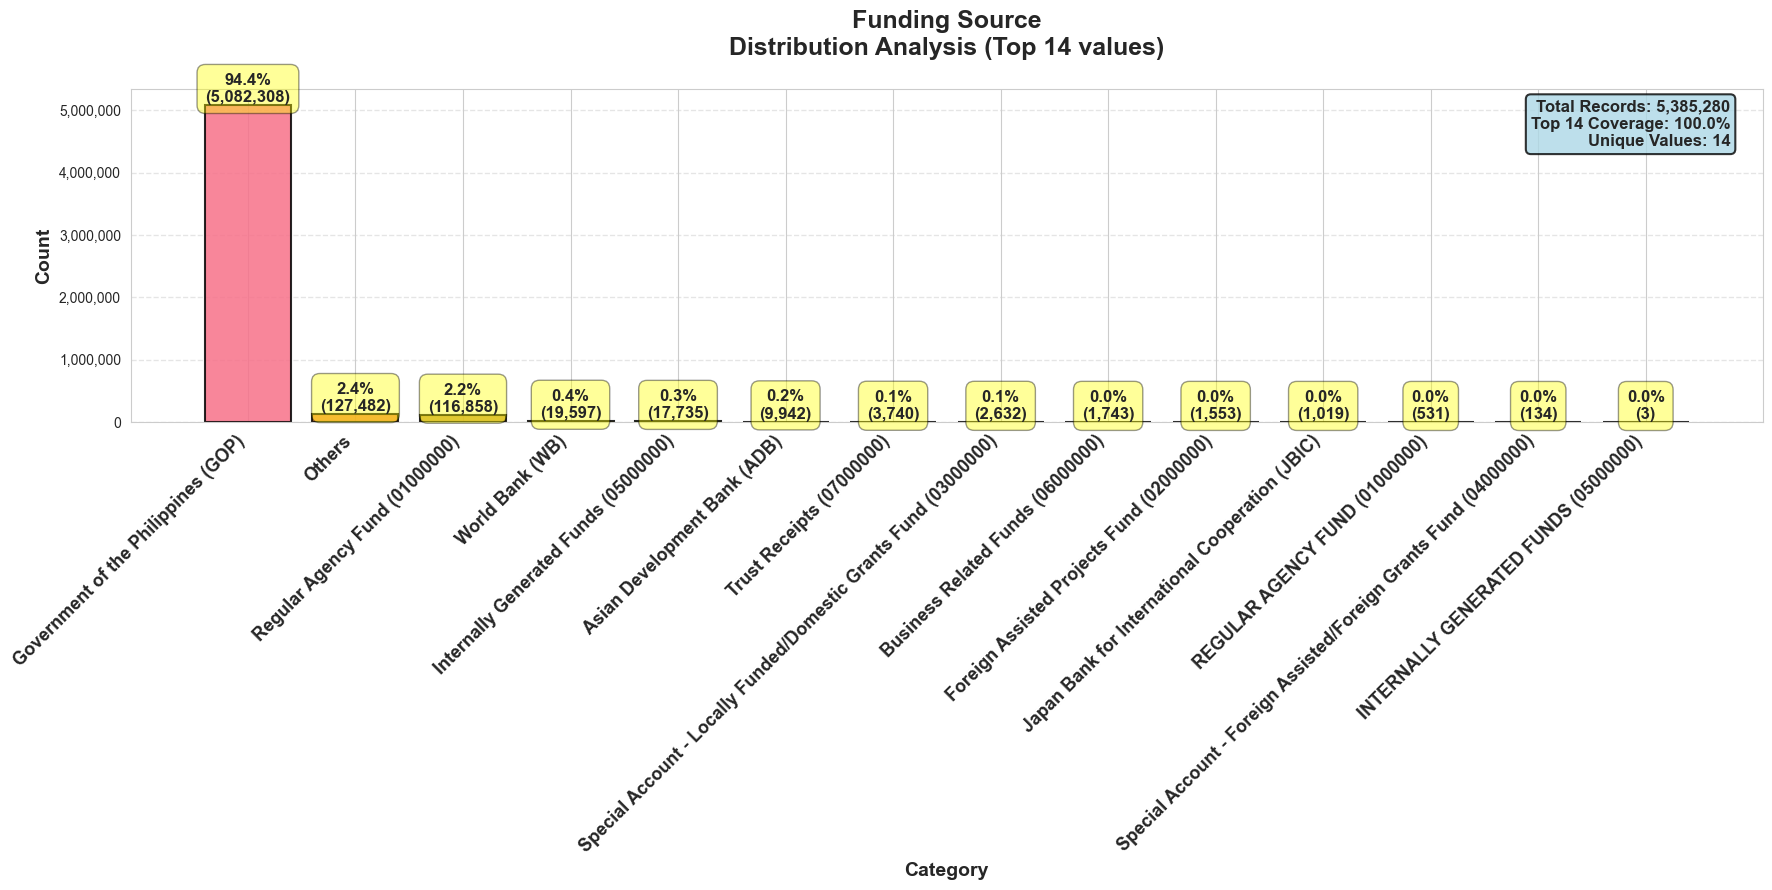


✓ All individual count plots created and saved separately!


In [7]:
print("\n" + "="*80)
print("COUNT ANALYSIS FOR EACH COLUMN")
print("="*80)

# Create separate graphs for each column
for idx, col in enumerate(available_cols):
    value_counts = merged_df_clean[col].value_counts()
    value_counts = value_counts[value_counts > 0]  # categoricals list unused categories with 0
    percentages = (value_counts / len(merged_df_clean) * 100).round(2)

    # Print summary
    print(f"\n{idx+1}. {col}")
    print("-" * 80)
    print(f"Unique values: {len(value_counts)}")
    
    summary_data = pd.DataFrame({
        'Value': value_counts.index[:10],
        'Count': value_counts.values[:10],
        'Percentage': percentages.values[:10]
    })
    print(summary_data.to_string(index=False))

    # Create individual figure for each column with larger size
    fig, ax = plt.subplots(figsize=(18, 9))
    
    top_n = min(15, len(value_counts))
    top_values = value_counts.head(top_n)
    top_percentages = percentages.head(top_n)
    
    # Create color gradient for better visibility
    colors = sns.color_palette('husl', len(top_values))
    
    bars = ax.bar(range(len(top_values)), top_values.values, color=colors, alpha=0.85, 
                   edgecolor='black', linewidth=1.5)

    # Add percentage and count labels on bars with better visibility
    for i, (v, p) in enumerate(zip(top_values.values, top_percentages.values)):
        ax.text(i, v, f'{p:.1f}%\n({v:,})', 
               ha='center', va='bottom', fontsize=12, fontweight='bold',
               bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.4, edgecolor='black'))

    ax.set_xticks(range(len(top_values)))
    ax.set_xticklabels(top_values.index, rotation=45, ha='right', fontsize=13, fontweight='bold')
    ax.set_title(f'{col}\nDistribution Analysis (Top {top_n} values)', 
                fontsize=18, fontweight='bold', pad=25)
    ax.set_ylabel('Count', fontsize=14, fontweight='bold')
    ax.set_xlabel('Category', fontsize=14, fontweight='bold')
    ax.grid(axis='y', alpha=0.5, linestyle='--', linewidth=1)
    ax.set_axisbelow(True)
    
    # Enhance y-axis formatting
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))
    
    # Add summary statistics box
    total_in_top = top_values.sum()
    total_percent = (total_in_top / len(merged_df_clean) * 100)
    stats_text = f'Total Records: {len(merged_df_clean):,}\nTop {top_n} Coverage: {total_percent:.1f}%\nUnique Values: {len(value_counts)}'
    ax.text(0.98, 0.97, stats_text,
           transform=ax.transAxes, fontsize=12, verticalalignment='top', horizontalalignment='right',
           bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.8, edgecolor='black', linewidth=1.5),
           fontweight='bold')
    
    plt.tight_layout()
    
    # Save individual plot with descriptive name
    safe_col_name = col.replace("/", "_").replace(" ", "_").replace("(", "").replace(")", "")
    plot_filename = FIG_DIR / f'plot_{idx+1:02d}_{safe_col_name}.png'
    plt.savefig(plot_filename, dpi=150, bbox_inches='tight')
    print(f"   ✓ Graph saved: plot_{idx+1:02d}_{safe_col_name}.png")
    
    plt.show()
    plt.close()

print("\n" + "="*80)
print("✓ All individual count plots created and saved separately!")
print("="*80)

## TASK 5: DATA SCOPING ANALYSIS FOR MODELING

In [8]:
print("="*80)
print("DATA SCOPING ANALYSIS FOR ML MODELING")
print("="*80)

print("""
OBJECTIVE: Predict the likelihood of procurement failure (a failed bidding) for PhilGEPS public biddings
GOAL: A notice-level risk score from information available at publication, for risk screening and review
      prioritisation. Not a model of whether a particular supplier will win, and not a bid recommender.

KEY INSIGHTS FOR DATA SCOPING:

1. **TEMPORAL SCOPE**
   - Dataset spans from 2023 to 2026 (3+ years of historical data)
   - Recommendation: Use 2023-2024 as training data, 2025-2026 for validation/test
   - Consider seasonality and procurement cycles (quarterly patterns visible)
   - Enable time-series validation: earlier data → prediction on later data

2. **GEOGRAPHIC SCOPE**
   - Multiple regions and provinces represented in the data
   - Recommendation: Start with national-level analysis
   - Then drill down to high-volume regions for more granular insights
   - Consider infrastructure and government presence variations by location

3. **ORGANIZATIONAL SCOPE (Procuring Entities)**
   - Different PE organization types have different procurement patterns
   - Recommendation: Stratify analysis by organization type
   - Consider separate models for different PE categories
   - Weight by organizational size/bidding volume

4. **PROCUREMENT MODE & CLASSIFICATION**
   - Different procurement modes (open bidding vs. negotiated procurement)
   - Different classification levels may have different contract completion rates
   - Recommendation: Filter for specific procurement modes most relevant to risk assessment
   - Focus on competitive bidding initially (higher data volume and standardization)

5. **FUNDING SOURCE**
   - Budget source might correlate with contract completion and project viability
   - Recommendation: Include as a feature; check for data quality/completeness
   - May need categorization or grouping for sparse categories

6. **DATA QUALITY ASSESSMENT**
   - Duplicates removed: {:.2f}% of original data
   - Missing values: Carefully handle by column importance
   - Long-tail distributions: Some columns have sparse representations
   - Recommendation: Use one-hot encoding or grouping for sparse categories

7. **SUGGESTED DATA SLICING STRATEGIES**

   OPTION A (Conservative - High Quality Focus):
   - Focus on major procurement modes (likely higher data quality)
   - Exclude small PE organizations with < 10 biddings
   - Use most recent 2 years of complete data (2024-2025)
   - Better for initial model development and validation

   OPTION B (Comprehensive - Maximum Learning):
   - Include all procurement modes (capture diverse risk scenarios)
   - Weight samples by time and procurement volume
   - Use 3+ years of historical data (2023-2026) with time-based validation
   - Better for understanding full spectrum of bidding behaviors

8. **TARGET VARIABLE ENGINEERING**
   - CRITICAL: Need to identify what "ended without contract" means in this dataset
   - Check for: completion status field, contract award indicators, bidding outcome
   - May need to infer from date ranges, project lifecycle indicators, or absence of records
   - Decision (adopted in notebooks/01): one label per bid. Failed = 1, Awarded = 0. Closed, Active,
     Cancelled, Shortlisted and conflicting notices are left unlabelled, NOT treated as failures;
     counting Cancelled as failure is run as a sensitivity check in notebooks/02

9. **FEATURE ENGINEERING OPPORTUNITIES**
   - Time-based: Bid duration, time of year, historical trends
   - Organization-based: PE bidding frequency, historical success rate, org type
   - Geographic: Region/province demand characteristics
   - Market-based: Seasonal/cyclical patterns, business category trends
   - Amount-based: Budget ranges, funding distribution, contract value ranges

10. **CLASS BALANCE CONSIDERATION**
   - Likely imbalanced target: most bids lead to contracts
   - Recommendation: Use stratified sampling, SMOTE, or class weights in model
   - Metric focus: Precision/Recall/F1 > Accuracy

11. **MODEL ARCHITECTURE RECOMMENDATIONS**
   - Start with: Logistic Regression, Random Forest, XGBoost
   - Advanced: Temporal models considering procurement cycles
   - Ensemble: Combine multiple models trained on different data slices
   - Risk stratification: Create 3-5 risk tiers instead of binary classification

12. **VALIDATION STRATEGY**
   - Adopted in notebooks/02: random 70/15/15 split of the merged 1.5 + 2.0 bid table, stratified by
     outcome and source system; notebooks/03 adds a time-based check (train 2023-2024, test 2025/2026)
   - Geographic hold-out: Train on major regions, test on underrepresented areas
   - Organization hold-out: Test on PE types not well-represented in training
   - Regular re-training needed as new procurement cycles emerge
""".format(duplicate_pct))

print("\n" + "="*80)

DATA SCOPING ANALYSIS FOR ML MODELING

OBJECTIVE: Predict the likelihood of procurement failure (a failed bidding) for PhilGEPS public biddings
GOAL: A notice-level risk score from information available at publication, for risk screening and review
      prioritisation. Not a model of whether a particular supplier will win, and not a bid recommender.

KEY INSIGHTS FOR DATA SCOPING:

1. **TEMPORAL SCOPE**
   - Dataset spans from 2023 to 2026 (3+ years of historical data)
   - Recommendation: Use 2023-2024 as training data, 2025-2026 for validation/test
   - Consider seasonality and procurement cycles (quarterly patterns visible)
   - Enable time-series validation: earlier data → prediction on later data

2. **GEOGRAPHIC SCOPE**
   - Multiple regions and provinces represented in the data
   - Recommendation: Start with national-level analysis
   - Then drill down to high-volume regions for more granular insights
   - Consider infrastructure and government presence variations by location


In [9]:
# Optional: save the de-duplicated dataset for future analysis.
# Parquet keeps the data types and is far smaller than CSV. data/processed/ is ignored by Git.
# output_path = ROOT / "data" / "processed" / "merged_cleaned_data.parquet"
# merged_df_clean.to_parquet(output_path, index=False)
# print(f"Saved to {output_path}")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)
print(f"\n✓ Cleaned dataset in memory: {merged_df_clean.shape[0]:,} rows × {merged_df_clean.shape[1]} columns")
print(f"✓ Count plots saved in: {FIG_DIR}")
print(f"\n✓ All tasks completed successfully!")


ANALYSIS COMPLETE

✓ Cleaned dataset in memory: 5,385,280 rows × 47 columns
✓ Count plots saved in: c:\Users\Deborah Argayosa\Documents\GitHub\philgeps-ml-project\data\processed\figures

✓ All tasks completed successfully!
